## EDA

In [22]:
# Import libraries
import pathlib

import numpy as np, pandas as pd, pathlib, json
import seaborn as sns, matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_selection import mutual_info_classif
import matplotlib; 

# Set theme for matplotlib
matplotlib.rcParams['figure.dpi']=120; sns.set_theme(style='whitegrid')

In [23]:
# path
PROC = pathlib.Path('../data/processed/liver_cleaned.csv')

In [24]:
df = pd.read_csv(PROC)
print(df.shape)
df.head(2)
# Recreate binary target for plots
# Dataset 1=liver, 2=no-liver → 1/0 for metrics
df['target'] = df['Dataset'].map({1:1,2:0})
df['target'].value_counts()

(570, 11)


target
1    406
0    164
Name: count, dtype: int64

### Univarirate + by disease - violin & kde

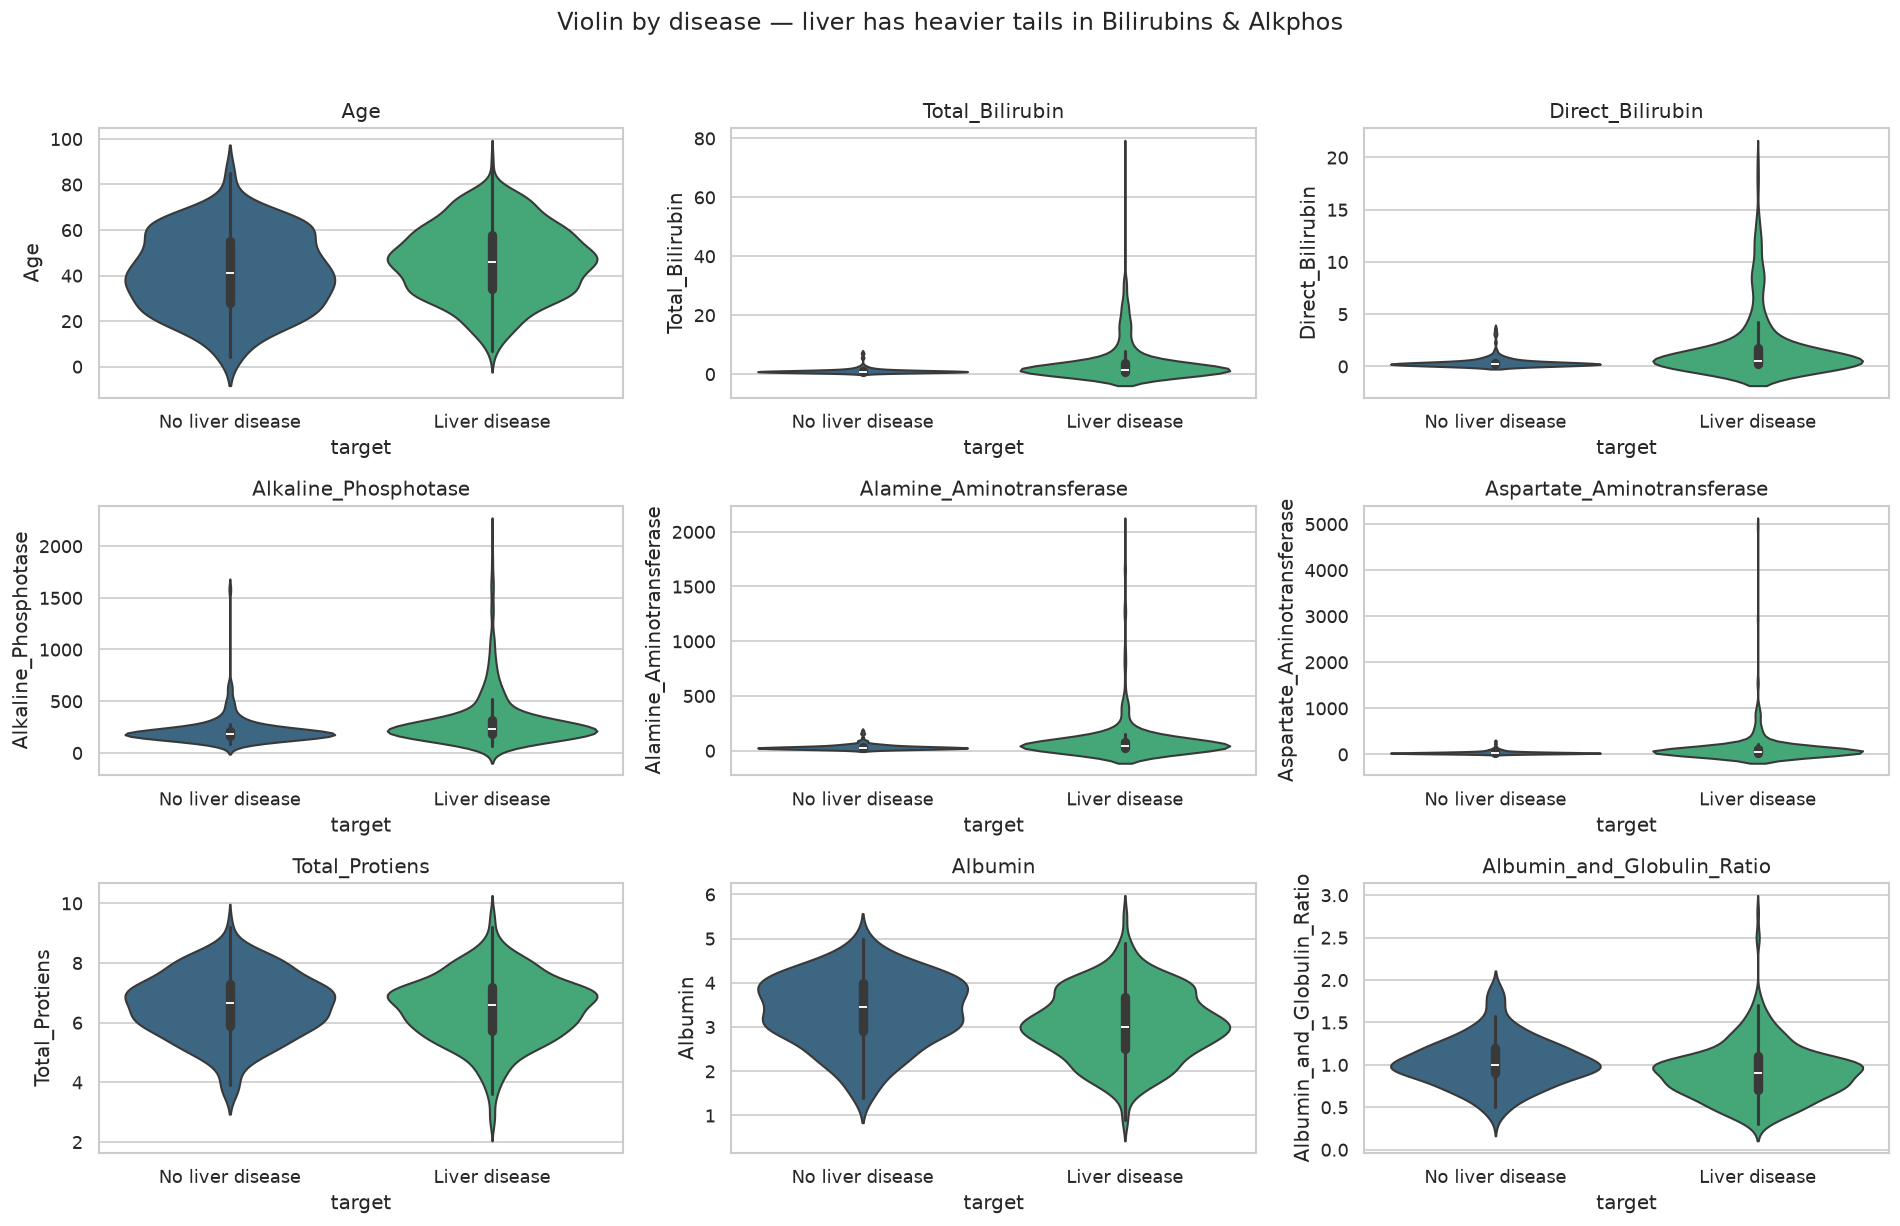

In [25]:

# Violin per feature split by disease — shows skew differences
fig, axes = plt.subplots(3, 3, figsize=(16, 10))

for ax, col in zip(axes.ravel(), num_cols):
    # Fix 1: Assign x to hue and disable the redundant legend
    sns.violinplot(
        data=df, 
        x='target', 
        y=col, 
        hue='target', 
        palette='viridis', 
        legend=False, 
        ax=ax
    )
    
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['No liver disease', 'Liver disease'])
    ax.set_title(col)

plt.suptitle('Violin by disease — liver has heavier tails in Bilirubins & Alkphos', y=1.02)
plt.tight_layout()
plt.show()


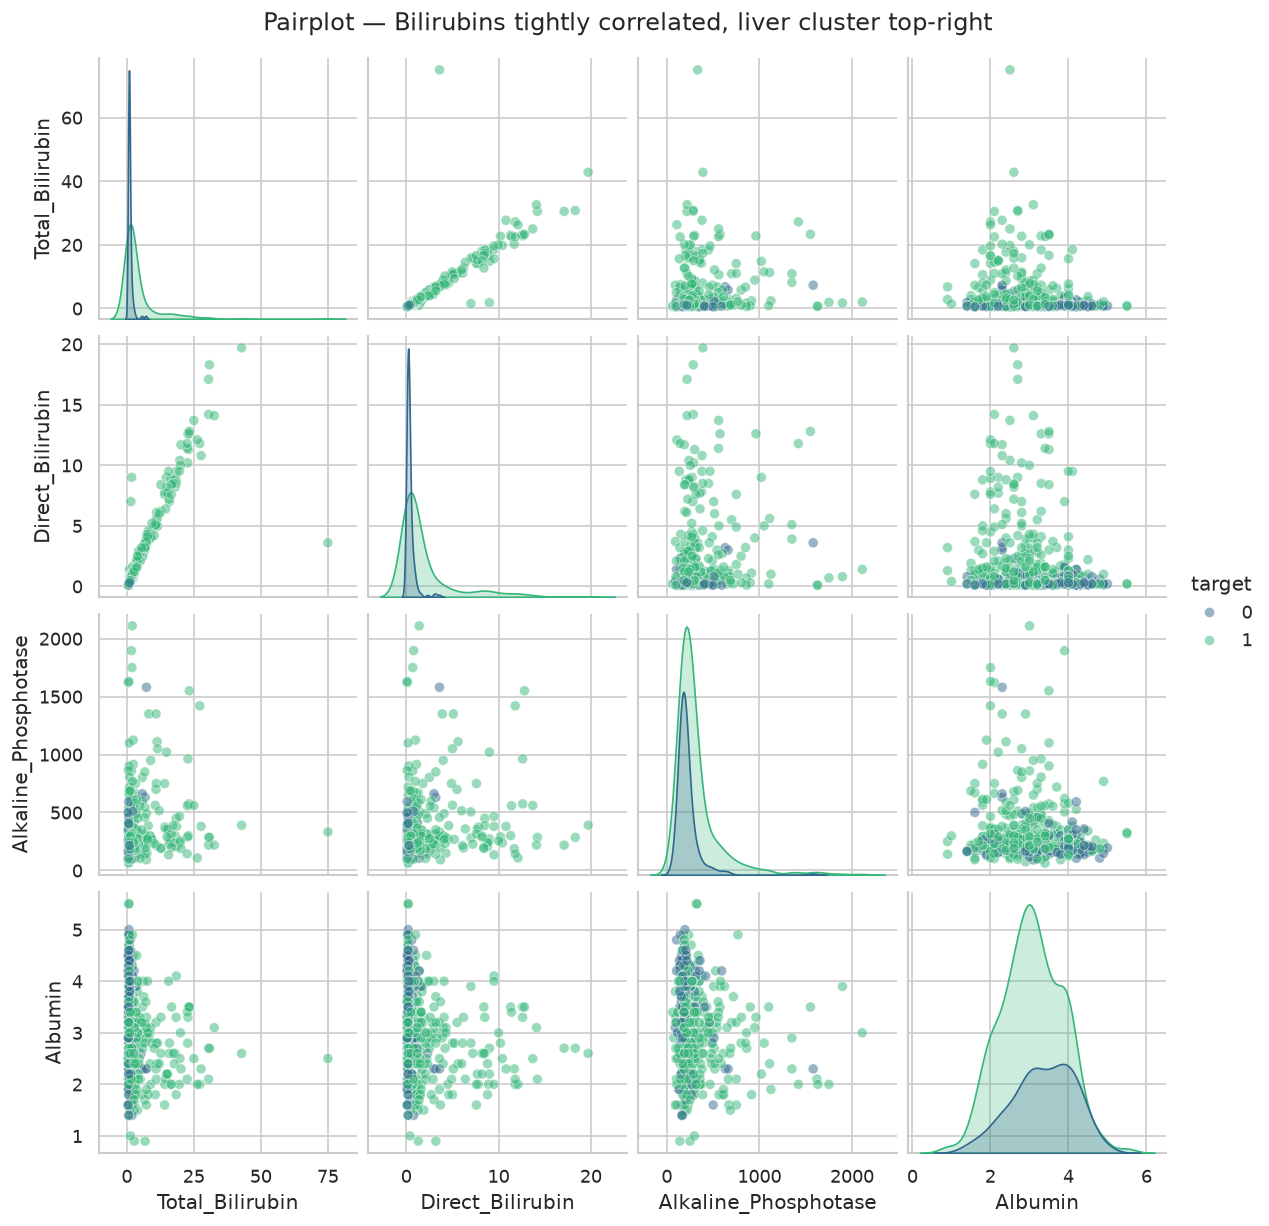

In [26]:
# Pairplot top 4 most informative (to avoid 9×9 clutter)
# Choose Bilirubins + Alkphos + Albumin per 01 VIF/mutual_info hint

sns.pairplot(df, vars=['Total_Bilirubin','Direct_Bilirubin','Alkaline_Phosphotase','Albumin'], hue='target', palette='viridis', diag_kind='kde', plot_kws={'alpha':0.5})
plt.suptitle('Pairplot — Bilirubins tightly correlated, liver cluster top-right', y=1.02)
plt.show()

### Mutual information ranking 

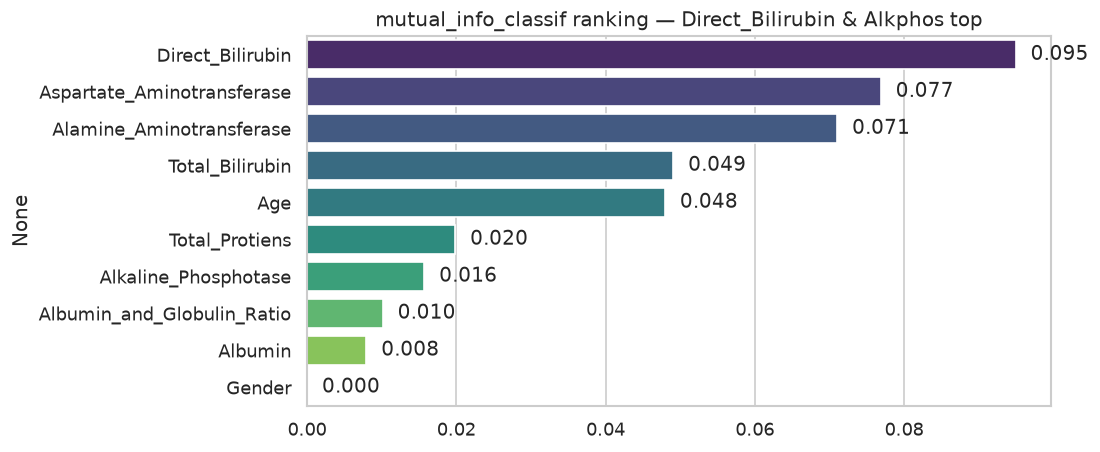

,mi
Direct_Bilirubin,0.094945
Aspartate_Aminotransferase,0.076872
Alamine_Aminotransferase,0.071029
Total_Bilirubin,0.049062
Age,0.047955
Total_Protiens,0.019848
Alkaline_Phosphotase,0.015702
Albumin_and_Globulin_Ratio,0.010138
Albumin,0.007939
Gender,0.000000


In [27]:

X = df.drop(columns=['Dataset', 'target']).copy()
y = df['target']
X['Gender'] = LabelEncoder().fit_transform(X['Gender'])
X['Albumin_and_Globulin_Ratio'] = X['Albumin_and_Globulin_Ratio'].fillna(X['Albumin_and_Globulin_Ratio'].median())

mi = mutual_info_classif(X, y, random_state=42)
mi_s = pd.Series(mi, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(8,4))
sns.barplot(x=mi_s.values, y=mi_s.index, hue=mi_s.index, palette='viridis', legend=False)
plt.title('mutual_info_classif ranking — Direct_Bilirubin & Alkphos top')

for i, v in enumerate(mi_s.values): 
    plt.text(v + 0.002, i, f"{v:.3f}", va='center')

plt.show()
display(mi_s.to_frame('mi'))

# Save for 03_feature_selection 


### Outlier, IQR clip fitted on train demo

In [28]:

# Demo: show effect of clipping Total_Bilirubin on train vs test
from sklearn.model_selection import train_test_split
train, test = train_test_split(df, test_size=0.2, stratify=df['target'], random_state=42)
for col in ['Total_Bilirubin','Alkaline_Phosphotase']:
    q1,q3 = train[col].quantile([0.25,0.75])
    iqr=q3-q1; lo,hi=q1-1.5*iqr,q3+1.5*iqr
    print(f"{col}: train hi clip {hi:.1f} — test beyond hi: {(test[col]>hi).mean():.1%}")

# Decision: we will use RobustScaler + optional IQR clip in Pipeline; not here


Total_Bilirubin: train hi clip 4.6 — test beyond hi: 21.9%
Alkaline_Phosphotase: train hi clip 464.0 — test beyond hi: 16.7%
